# CrediScope Analysis

**Clear decisions. Clear reasons.**

This notebook explores the CreditSense dataset and prepares the data for machine learning.

The aim is to understand the structure of the dataset, identify any issues that need preprocessing, and prepare the features before training a credit-risk model.

In [92]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [93]:
df = pd.read_csv("../data/creditsense_applications.csv")
dictionary = pd.read_csv("../data/creditsense_data_dictionary.csv")

In [94]:
df.shape

(6000, 27)

In [95]:
df.head()

,application_id,age_years,sex,marital_status,residency_status,num_dependents,region,employment_status,months_in_current_job,annual_income_gbp,...,has_savings_account,savings_balance_gbp,checking_account_status,loan_amount_gbp,loan_term_months,loan_purpose,has_guarantor,previous_application_declined,application_channel,default_within_24m
0,APP-000001,34,Female,Married,Settled Status,1,North West,Permanent,19,66550,...,Yes,380.0,500 GBP or more,13100,36,Home improvement,No,No,Online,0
1,APP-000002,43,Female,Married,Settled Status,1,South East,Permanent,29,20820,...,No,0.0,Overdrawn,9700,60,Medical,No,No,Branch,1
2,APP-000003,47,Male,Single,UK Citizen,0,South East,Permanent,115,32710,...,No,0.0,500 GBP or more,8600,36,Home improvement,No,No,Online,0
3,APP-000004,63,Male,Married,UK Citizen,1,London,Permanent,146,47300,...,Yes,NaN,0 to 500 GBP,25600,36,Home improvement,No,No,Online,0
4,APP-000005,40,Male,Single,UK Citizen,1,Yorkshire,Permanent,22,41400,...,Yes,860.0,0 to 500 GBP,3500,36,Car,Yes,No,Branch,0


In [96]:
df.columns.tolist()

['application_id',
 'age_years',
 'sex',
 'marital_status',
 'residency_status',
 'num_dependents',
 'region',
 'employment_status',
 'months_in_current_job',
 'annual_income_gbp',
 'monthly_expenses_gbp',
 'housing_status',
 'years_at_current_address',
 'existing_debt_gbp',
 'num_existing_credit_lines',
 'num_late_payments_24m',
 'credit_history',
 'has_savings_account',
 'savings_balance_gbp',
 'checking_account_status',
 'loan_amount_gbp',
 'loan_term_months',
 'loan_purpose',
 'has_guarantor',
 'previous_application_declined',
 'application_channel',
 'default_within_24m']

In [97]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 27 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   application_id                 6000 non-null   str    
 1   age_years                      6000 non-null   int64  
 2   sex                            6000 non-null   str    
 3   marital_status                 6000 non-null   str    
 4   residency_status               6000 non-null   str    
 5   num_dependents                 6000 non-null   int64  
 6   region                         6000 non-null   str    
 7   employment_status              6000 non-null   str    
 8   months_in_current_job          6000 non-null   int64  
 9   annual_income_gbp              6000 non-null   int64  
 10  monthly_expenses_gbp           6000 non-null   int64  
 11  housing_status                 6000 non-null   str    
 12  years_at_current_address       5832 non-null   float64
 13 

In [98]:
df.isna().sum().sort_values(ascending=False)

savings_balance_gbp              258
years_at_current_address         168
application_id                     0
marital_status                     0
residency_status                   0
num_dependents                     0
region                             0
employment_status                  0
months_in_current_job              0
age_years                          0
sex                                0
monthly_expenses_gbp               0
annual_income_gbp                  0
existing_debt_gbp                  0
housing_status                     0
num_existing_credit_lines          0
num_late_payments_24m              0
credit_history                     0
has_savings_account                0
checking_account_status            0
loan_amount_gbp                    0
loan_term_months                   0
loan_purpose                       0
has_guarantor                      0
previous_application_declined      0
application_channel                0
default_within_24m                 0
d

## Missing Values

Only two features contain missing values:

- `savings_balance_gbp` has 258 missing values.
- `years_at_current_address` has 168 missing values.

All other columns are complete.

These missing values will be investigated before deciding how they should be handled during preprocessing.

In [99]:
df["default_within_24m"].value_counts()

default_within_24m
0    4467
1    1533
Name: count, dtype: int64

In [100]:
df["default_within_24m"].value_counts(normalize=True) * 100

default_within_24m
0    74.45
1    25.55
Name: proportion, dtype: float64

## Target Variable

The target variable is `default_within_24m`.

- `0` means the applicant did not default within 24 months.
- `1` means the applicant did default within 24 months.

The target is moderately imbalanced, with 25.55% of applicants in the default class.

In [101]:
dictionary.head(30)

,column,type,description,protected_attribute,notes
0,application_id,string,Unique application reference,No,Identifier only - must NOT be used as a feature
1,age_years,integer,Applicant age at application,Yes,Protected characteristic under Equality Act 2010
2,sex,categorical,Female / Male,Yes,Protected characteristic under Equality Act 2010
3,marital_status,categorical,Single / Married / Divorced / Widowed,Yes,Correlates strongly with age
4,residency_status,categorical,UK Citizen / Settled Status / Visa Holder,Yes,Proxy for nationality - protected characteristic
5,num_dependents,integer,Number of financial dependents,No,Correlates with marital_status
6,region,categorical,UK region of residence,No,Can act as a proxy for other attributes
7,employment_status,categorical,Permanent / Fixed-term / Self-employed / Zero-...,No,Retired appears only in older applicants
8,months_in_current_job,integer,Tenure in current employment (months),No,Zero for unemployed applicants - structural ze...
9,annual_income_gbp,integer,Gross annual income in GBP,No,Not adjusted for region


## Initial Data Dictionary Observations

The data dictionary highlights several features that will need careful handling during preprocessing.

- `application_id` is an identifier and should not be used as a predictive feature.
- `age_years`, `sex`, `marital_status`, `residency_status` and `housing_status` are marked as protected attributes.
- `region` is not marked as protected, but it may act as a proxy for other characteristics.
- `credit_history` is ordinal.
- `checking_account_status` is ordinal, but the `No account` category does not fit naturally on the same ordered scale.
- `months_in_current_job = 0` for unemployed applicants is a structural zero and represents valid information.
- Missing values occur in `years_at_current_address` and `savings_balance_gbp`.

In [102]:
numerical_columns = df.select_dtypes(
   include=["int64", "float64"] 
).columns.tolist()

categorical_columns = df.select_dtypes(
   include="str" 
).columns.tolist()

In [103]:
print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)


Numerical Columns:
['age_years', 'num_dependents', 'months_in_current_job', 'annual_income_gbp', 'monthly_expenses_gbp', 'years_at_current_address', 'existing_debt_gbp', 'num_existing_credit_lines', 'num_late_payments_24m', 'savings_balance_gbp', 'loan_amount_gbp', 'loan_term_months', 'default_within_24m']

Categorical Columns:
['application_id', 'sex', 'marital_status', 'residency_status', 'region', 'employment_status', 'housing_status', 'credit_history', 'has_savings_account', 'checking_account_status', 'loan_purpose', 'has_guarantor', 'previous_application_declined', 'application_channel']


In [104]:
target_column = "default_within_24m"
id_column = "application_id"

numerical_features = [
    col for col in numerical_columns 
    if col not in [target_column, id_column]
]

categorical_features = [
    col for col in categorical_columns
    if col != id_column
]

In [105]:
print("Numerical Columns:") 
print(numerical_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Columns:
['age_years', 'num_dependents', 'months_in_current_job', 'annual_income_gbp', 'monthly_expenses_gbp', 'years_at_current_address', 'existing_debt_gbp', 'num_existing_credit_lines', 'num_late_payments_24m', 'savings_balance_gbp', 'loan_amount_gbp', 'loan_term_months']

Categorical Columns:
['sex', 'marital_status', 'residency_status', 'region', 'employment_status', 'housing_status', 'credit_history', 'has_savings_account', 'checking_account_status', 'loan_purpose', 'has_guarantor', 'previous_application_declined', 'application_channel']


## Feature Groups

The dataset contains 25 predictive features.

- 12 numerical features
- 13 categorical features
- `application_id` is excluded because it is only an identifier
- `default_within_24m` is the target variable

# Data Preprocessing

This section prepares the dataset for machine learning.

A separate working copy of the original dataframe will be used so that the raw data remains unchanged while preprocessing decisions are applied.

In [106]:
df_clean = df.copy()

In [107]:
print("Original dataset shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Original dataset shape: (6000, 27)
Working copy shape: (6000, 27)


In [108]:
df_clean.isna().sum()[df_clean.isna().sum() >0]

years_at_current_address    168
savings_balance_gbp         258
dtype: int64

## Missing Value Investigation

Two features contain missing values:

- `years_at_current_address`
- `savings_balance_gbp`

Before filling these values, their distributions and meanings will be checked to choose an appropriate preprocessing method.

In [109]:
df_clean["years_at_current_address"].describe()

count    5832.000000
mean        5.169513
std         4.893061
min         0.000000
25%         1.900000
50%         3.700000
75%         6.800000
max        40.000000
Name: years_at_current_address, dtype: float64

In [110]:
df_clean["savings_balance_gbp"].describe()

count      5742.000000
mean       3206.849530
std        7875.004884
min           0.000000
25%           0.000000
50%         610.000000
75%        3250.000000
max      160000.000000
Name: savings_balance_gbp, dtype: float64

In [111]:
df_clean.groupby("has_savings_account")["savings_balance_gbp"].apply(
    lambda x: x.isna().sum()
)

has_savings_account
No       0
Yes    258
Name: savings_balance_gbp, dtype: int64

## Missing Value Decision

The two features with missing values are `years_at_current_address` and `savings_balance_gbp`.

Both features are positively skewed, so the median is preferred to the mean because it is less affected by large values.

For `savings_balance_gbp`, all missing values occur among applicants who do have a savings account. Applicants without a savings account already have a meaningful balance of £0, so those zeros must be preserved.

In [112]:
df_clean["years_at_current_address"] = (
    df_clean["years_at_current_address"]
    .fillna(df_clean["years_at_current_address"].median())
)

df_clean["savings_balance_gbp"] = (
    df_clean["savings_balance_gbp"]
    .fillna(df_clean["savings_balance_gbp"].median())
)

In [113]:
df_clean[
    ["years_at_current_address", "savings_balance_gbp"]
].isna().sum()

years_at_current_address    0
savings_balance_gbp         0
dtype: int64

In [114]:
df_clean.isna().sum().sum()

np.int64(0)

### Missing Value Result

Median imputation was applied to the two features containing missing values.

After preprocessing, the working dataset contains no missing values.

In [115]:
df_clean.groupby("employment_status")["months_in_current_job"].describe()

,count,mean,std,min,25%,50%,75%,max
employment_status,,,,,,,,
Fixed-term,606.0,21.016502,13.643140,2.0,11.0,17.0,29.0,89.0
Permanent,4125.0,53.890667,34.846809,3.0,28.0,46.0,73.0,245.0
Retired,77.0,111.389610,44.850382,41.0,74.0,109.0,136.0,242.0
Self-employed,679.0,55.587629,37.494002,3.0,30.0,46.0,72.0,250.0
Unemployed,227.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
Zero-hours,286.0,21.363636,13.552003,1.0,11.0,19.0,30.0,83.0


## Structural Zero Check

The `months_in_current_job` feature contains zero values for unemployed applicants.

All 227 unemployed applicants have `months_in_current_job = 0`, which indicates that these values are structural zeros rather than missing data.

These values will therefore be preserved.

In [116]:
binary_columns = [
    "has_savings_account",
    "has_guarantor",
    "previous_application_declined",
]

In [117]:
for col in binary_columns:
    df_clean[col] = df_clean[col].map({"Yes": 1, "No": 0})

In [118]:
for col in binary_columns:
    print(col, df_clean[col].value_counts())

has_savings_account has_savings_account
1    3495
0    2505
Name: count, dtype: int64
has_guarantor has_guarantor
0    5432
1     568
Name: count, dtype: int64
previous_application_declined previous_application_declined
0    5251
1     749
Name: count, dtype: int64


## Binary Feature Encoding

Three Yes/No categorical features were converted to numerical binary values:

- `has_savings_account`
- `has_guarantor`
- `previous_application_declined`

`Yes` was encoded as `1` and `No` as `0`.

In [119]:
df_clean["credit_history"].value_counts()

credit_history
Existing credits paid    1935
All paid on time         1727
Past delays              1356
No credits taken          882
Critical account          100
Name: count, dtype: int64

## Ordinal Encoding

The `credit_history` feature has categories that represent different levels of credit risk.

An ordinal encoding will be used so that lower values represent better credit history and higher values represent greater risk.

Proposed order:

1. `All paid on time`
2. `Existing credits paid`
3. `No credits taken`
4. `Past delays`
5. `Critical account`

In [120]:
credit_history_mapping = {
    "All paid on time": 0,
    "Existing credits paid": 1,
    "No credits taken": 2,
    "Past delays": 3,
    "Critical account": 4,
}

In [121]:
df_clean["credit_history"].value_counts().sort_index()

credit_history
All paid on time         1727
Critical account          100
Existing credits paid    1935
No credits taken          882
Past delays              1356
Name: count, dtype: int64

In [122]:
df_clean["credit_history"].isna().sum()

np.int64(0)

In [123]:
df_clean["checking_account_status"].value_counts()

checking_account_status
0 to 500 GBP       2185
500 GBP or more    1971
Overdrawn          1252
No account          592
Name: count, dtype: int64

### Checking Account Status

The `checking_account_status` feature contains three naturally ordered categories:

- `Overdrawn`
- `0 to 500 GBP`
- `500 GBP or more`

The category `No account` does not fit naturally on the same ordinal scale.

To preserve this distinction, `No account` will be handled separately rather than being forced into the ordered ranking.

In [124]:
df_clean["has_checking_account"] = (
    df_clean["checking_account_status"] != "No account"
).astype(int)

In [125]:
df_clean["has_checking_account"].value_counts()

has_checking_account
1    5408
0     592
Name: count, dtype: int64

In [126]:
checking_status_mapping = {
    "Overdrawn": 0,
    "0 to 500 GBP": 1,
    "500 GBP or more": 2,
}

In [127]:
df_clean["checking_account_status"] = (
    df_clean["checking_account_status"]
    .map(checking_status_mapping)
)

In [128]:
df_clean["checking_account_status"].value_counts(dropna=False).sort_index()

checking_account_status
0.0    1252
1.0    2185
2.0    1971
NaN     592
Name: count, dtype: int64

In [129]:
df_clean["checking_account_status"] = (
    df_clean["checking_account_status"]
    .fillna(0)
    .astype(int)
)

In [130]:
df_clean[
    ["checking_account_status", "has_checking_account"]
].value_counts().sort_index()

checking_account_status  has_checking_account
0                        0                        592
                         1                       1252
1                        1                       2185
2                        1                       1971
Name: count, dtype: int64

### Checking Account Encoding Result

The ordered checking account categories were encoded numerically, while `No account` was separated using the `has_checking_account` indicator.

This preserves the distinction between:

- applicants with no checking account
- applicants who are overdrawn
- applicants with lower balances
- applicants with higher balances

In [131]:
remaining_categorical = df_clean.select_dtypes(include="object").columns.tolist()

remaining_categorical

C:\Users\Richa\AppData\Local\Temp\ipykernel_2800\448189261.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  remaining_categorical = df_clean.select_dtypes(include="object").columns.tolist()


['application_id',
 'sex',
 'marital_status',
 'residency_status',
 'region',
 'employment_status',
 'housing_status',
 'credit_history',
 'loan_purpose',
 'application_channel']

In [132]:
df_clean["credit_history"].head(10)

0    Existing credits paid
1         All paid on time
2         No credits taken
3    Existing credits paid
4              Past delays
5    Existing credits paid
6              Past delays
7              Past delays
8         All paid on time
9    Existing credits paid
Name: credit_history, dtype: str

In [133]:
df_clean["credit_history"] = df_clean["credit_history"].map(
    credit_history_mapping
)

In [134]:
df_clean["credit_history"].value_counts().sort_index()

credit_history
0    1727
1    1935
2     882
3    1356
4     100
Name: count, dtype: int64

In [135]:
df_clean["credit_history"].isna().sum()

np.int64(0)

In [136]:
remaining_categorical = df_clean.select_dtypes(include="str").columns.tolist()

remaining_categorical

['application_id',
 'sex',
 'marital_status',
 'residency_status',
 'region',
 'employment_status',
 'housing_status',
 'loan_purpose',
 'application_channel']

In [137]:
nominal_features = [
    "region",
    "employment_status",
    "loan_purpose",
    "application_channel",
]

## Nominal Categorical Features

The following features have categories with no natural ranking:

- `region`
- `employment_status`
- `loan_purpose`
- `application_channel`

These features will be prepared using one-hot encoding.

Other categorical features such as `sex`, `marital_status`, `residency_status` and `housing_status` require a separate modelling decision because of their protected or sensitive nature.

## Protected and Sensitive Attributes

Several categorical features are identified as protected or sensitive within the data dictionary.

These features will not be used directly as predictive inputs in the initial model:

- `sex`
- `marital_status`
- `residency_status`
- `housing_status`

They will be retained in the dataset for later fairness analysis.

`region` is not formally marked as protected, but it may act as a proxy for other characteristics, so its use will be considered carefully.

In [138]:
protected_features = [
    "sex",
    "marital_status",
    "residency_status",
    "housing_status"
]

In [139]:
excluded_features = [
    "application_id",
    "default_within_24m",
] + protected_features

In [140]:
model_features = [
    col for col in df_clean.columns 
    if col not in excluded_features
]

In [141]:
model_features

['age_years',
 'num_dependents',
 'region',
 'employment_status',
 'months_in_current_job',
 'annual_income_gbp',
 'monthly_expenses_gbp',
 'years_at_current_address',
 'existing_debt_gbp',
 'num_existing_credit_lines',
 'num_late_payments_24m',
 'credit_history',
 'has_savings_account',
 'savings_balance_gbp',
 'checking_account_status',
 'loan_amount_gbp',
 'loan_term_months',
 'loan_purpose',
 'has_guarantor',
 'previous_application_declined',
 'application_channel',
 'has_checking_account']

In [142]:
protected_features = [
    "age_years",
    "sex",
    "marital_status",
    "residency_status",
    "housing_status"
]

In [143]:
excluded_features = [
    "application_id",
    "default_within_24m"
] + protected_features

In [144]:
model_features = [
    col for col in df_clean.columns
    if col not in excluded_features
]

In [145]:
model_features

['num_dependents',
 'region',
 'employment_status',
 'months_in_current_job',
 'annual_income_gbp',
 'monthly_expenses_gbp',
 'years_at_current_address',
 'existing_debt_gbp',
 'num_existing_credit_lines',
 'num_late_payments_24m',
 'credit_history',
 'has_savings_account',
 'savings_balance_gbp',
 'checking_account_status',
 'loan_amount_gbp',
 'loan_term_months',
 'loan_purpose',
 'has_guarantor',
 'previous_application_declined',
 'application_channel',
 'has_checking_account']

## Initial Model Feature Set

The initial model excludes:

- `application_id`
- the target variable `default_within_24m`
- protected attributes identified in the data dictionary

The remaining features form the initial modelling feature set.

`region` is retained at this stage, but it may act as a proxy for protected characteristics and will be reviewed during fairness analysis.

In [147]:
nominal_features

['region', 'employment_status', 'loan_purpose', 'application_channel']

In [148]:
df_clean = pd.get_dummies(
    df_clean,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)

In [149]:
df_clean.shape

(6000, 48)

In [150]:
[col for col in df_clean.columns if col.startswith("region_")][:10]

['region_Midlands',
 'region_North East',
 'region_North West',
 'region_Northern Ireland',
 'region_Scotland',
 'region_South East',
 'region_South West',
 'region_Wales',
 'region_Yorkshire']

## One-Hot Encoding

The nominal categorical features were converted into binary indicator columns using one-hot encoding.

The encoded features were:

- `region`
- `employment_status`
- `loan_purpose`
- `application_channel`

`drop_first=True` was used so that one category from each feature acts as a reference category, reducing redundant information.

The dataset increased from 27 columns to 48 columns while retaining all 6,000 application records.

In [152]:
df_clean.select_dtypes(include="object").columns.tolist()

C:\Users\Richa\AppData\Local\Temp\ipykernel_2800\2435950628.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_clean.select_dtypes(include="object").columns.tolist()


['application_id',
 'sex',
 'marital_status',
 'residency_status',
 'housing_status']

### Encoding Check

After one-hot encoding, the only remaining text columns are the application identifier and protected/sensitive attributes.

These columns are not included directly in the initial predictive model.

In [154]:
df_clean["debt_to_income_ratio"] = (
    df_clean["existing_debt_gbp"] /
    df_clean["annual_income_gbp"]
)

In [155]:
df_clean["debt_to_income_ratio"].describe()

count    6000.000000
mean        0.307106
std         0.284312
min         0.000000
25%         0.000000
50%         0.261718
75%         0.560400
max         0.849748
Name: debt_to_income_ratio, dtype: float64

## Feature Engineering

A `debt_to_income_ratio` feature was created by dividing existing debt by annual income.

This provides a relative measure of debt burden, which may be more informative than considering debt or income separately.

In [156]:
df_clean["expenses_to_income_ratio"] = (
    df_clean["monthly_expenses_gbp"] * 12 /
    df_clean["annual_income_gbp"]
)    

In [157]:
df_clean["expenses_to_income_ratio"].describe()

count    6000.000000
mean        0.788505
std         0.359927
min         0.340003
25%         0.566188
50%         0.704567
75%         0.921250
max         4.596923
Name: expenses_to_income_ratio, dtype: float64

In [158]:
df_clean = df_clean.rename(
    columns={"expenses_to_income_ratio": "expense_to_income_ratio"}
)

In [159]:
"expense_to_income_ratio" in df_clean.columns

True

In [160]:
df_clean[df_clean["expense_to_income_ratio"] > 1][
    [
        "annual_income_gbp",
        "monthly_expenses_gbp",
        "expense_to_income_ratio"
    ]
].head(10)    

,annual_income_gbp,monthly_expenses_gbp,expense_to_income_ratio
1,20820,2460,1.417867
16,29280,3140,1.286885
32,17950,1690,1.129805
33,29240,2460,1.009576
52,12560,1330,1.270701
59,16610,2160,1.560506
61,16160,1560,1.158416
68,31540,2700,1.027267
73,25960,2390,1.104777
74,12580,1650,1.573927


In [161]:
(df_clean["expense_to_income_ratio"] > 1).sum()

np.int64(1123)

### Expense-to-Income Ratio

An `expense_to_income_ratio` feature was created by annualising monthly expenses and dividing them by annual income.

Some applicants have a ratio greater than 1, meaning their stated annual expenses exceed their annual income.

This occurs for 1,123 applicants, so it is treated as a meaningful characteristic of the dataset rather than an isolated data error.

## Train/Test Split

The dataset will now be separated into training and testing sets.

The training data will be used to fit the machine-learning model, while the test data will be kept separate so that model performance can be evaluated on unseen applications.

In [162]:
from sklearn.model_selection import train_test_split

In [171]:
X = df_clean.drop(
    columns=[
        "application_id",
        "default_within_24m",
        "age_years",
        "sex",
        "marital_status",
        "residency_status",
        "housing_status"
    ]
)

y = df_clean["default_within_24m"]

In [172]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (6000, 43)
y shape: (6000,)


In [173]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [174]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4800, 43)
X_test: (1200, 43)
y_train: (4800,)
y_test: (1200,)


In [175]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
default_within_24m
0    74.458333
1    25.541667
Name: proportion, dtype: float64

Testing target distribution:
default_within_24m
0    74.416667
1    25.583333
Name: proportion, dtype: float64


### Split Verification

A stratified 80/20 train-test split was used.

The class distribution was preserved across both datasets, with approximately 74% non-default cases and 26% default cases in both the training and testing sets.

This helps ensure that model evaluation is performed on a representative test set.

In [176]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [177]:
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

In [178]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](43,)","['num_dependents','months_in_current_job','annual_income_gbp',..., 'application_channel_Phone','debt_to_income_ratio', 'expense_to_income_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,43
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [179]:
y_pred = baseline_model.predict(X_test)

In [180]:
from sklearn.metrics import accuracy_score

In [181]:
accurancy = accuracy_score(y_test, y_pred)

print("Baseline Model Accuracy:", accurancy)

Baseline Model Accuracy: 0.8


In [182]:
from sklearn.metrics import classification_report

In [183]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.92      0.87       893
           1       0.65      0.46      0.54       307

    accuracy                           0.80      1200
   macro avg       0.74      0.69      0.71      1200
weighted avg       0.79      0.80      0.79      1200



### Baseline Classification Performance

The baseline Logistic Regression model achieved an accuracy of 80%.

However, performance differed between the two classes.

For applicants who defaulted (`class 1`), the model achieved:

- Precision: 0.65
- Recall: 0.46
- F1-score: 0.54

The relatively low recall means the model fails to identify more than half of the applicants who later default.

This shows why accuracy alone is not sufficient for evaluating the model.


In [184]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, y_pred)

array([[818,  75],
       [165, 142]])

### Confusion Matrix Interpretation

The confusion matrix for the baseline Logistic Regression model produced:

- 818 true negatives
- 75 false positives
- 165 false negatives
- 142 true positives

The most significant weakness is the 165 false negatives. These are applicants who actually defaulted but were predicted as non-default.

This supports the earlier finding that the baseline model has relatively low recall for the default class and may fail to identify a substantial number of higher-risk applicants.

In [187]:
from sklearn.metrics import roc_auc_score

In [188]:
y_prob = baseline_model.predict_proba(X_test)[:, 1]

In [189]:
roc_auc = roc_auc_score(y_test, y_prob)

print("Baseline ROC AUC Score:", roc_auc)

Baseline ROC AUC Score: 0.8111259853146624


### ROC-AUC

The baseline Logistic Regression model achieved a ROC-AUC score of approximately 0.81.

This indicates that the model has a reasonably strong ability to distinguish between applicants who default and those who do not.

However, this does not remove the concern identified in the confusion matrix, where the model missed a substantial number of actual default cases.

In [190]:
from sklearn.ensemble import RandomForestClassifier

In [193]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)    

In [194]:
random_forest_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [195]:
rf_pred = random_forest_model.predict(X_test)

In [196]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.795


In [197]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86       893
           1       0.60      0.60      0.60       307

    accuracy                           0.80      1200
   macro avg       0.73      0.73      0.73      1200
weighted avg       0.80      0.80      0.80      1200



In [198]:
confusion_matrix(y_test, rf_pred)

array([[770, 123],
       [123, 184]])

### Random Forest Confusion Matrix

The Random Forest confusion matrix produced:

- 770 true negatives
- 123 false positives
- 123 false negatives
- 184 true positives

Compared with the Logistic Regression baseline, the Random Forest identifies more applicants who actually default, reducing false negatives from 165 to 123.

However, this improvement comes at a cost, as false positives increase from 75 to 123.

This demonstrates a trade-off between identifying more high-risk applicants and potentially classifying more low-risk applicants as likely to default.

In [199]:
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest ROC-AUC:", rf_roc_auc)

Random Forest ROC-AUC: 0.8188917786183526


### Baseline Model Comparison

The Logistic Regression and Random Forest models produced similar overall accuracy, but their error patterns differed.

The Random Forest achieved slightly lower accuracy but improved recall for the default class from 0.46 to 0.60 and improved the F1-score from 0.54 to 0.60.

It also reduced false negatives from 165 to 123, meaning it identified more applicants who later defaulted.

However, false positives increased from 75 to 123, meaning more applicants who would not default were incorrectly classified as higher risk.

The Random Forest also achieved a slightly higher ROC-AUC score of approximately 0.819 compared with 0.811 for Logistic Regression.

This highlights a trade-off between improved detection of default risk and the increased likelihood of incorrectly flagging lower-risk applicants.

## Model Selection and Constraints

The Random Forest currently provides the stronger predictive performance for identifying applicants who default.

It improves recall and F1-score for the default class and reduces the number of false negatives compared with Logistic Regression.

However, Random Forest is less transparent because predictions are produced from many decision trees rather than a single set of easily interpretable coefficients.

Logistic Regression is easier to explain and audit, which is important in a regulated credit-risk environment.

Therefore, model selection should not be based on predictive performance alone. The final choice must consider:

- predictive performance
- false positives and false negatives
- explainability
- fairness
- regulatory defensibility
- suitability for adverse-action explanations

At this stage, Random Forest is the stronger predictive candidate, while Logistic Regression remains the stronger candidate for transparency and interpretability.

In [200]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance.head(10)

,feature,importance
42,expense_to_income_ratio,0.176547
2,annual_income_gbp,0.096686
41,debt_to_income_ratio,0.067738
12,loan_amount_gbp,0.066052
3,monthly_expenses_gbp,0.060932
5,existing_debt_gbp,0.057495
1,months_in_current_job,0.054789
4,years_at_current_address,0.051248
7,num_late_payments_24m,0.046247
13,loan_term_months,0.037004


### Random Forest Feature Importance

The most important feature in the Random Forest model was `expense_to_income_ratio`, followed by `annual_income_gbp`, `debt_to_income_ratio`, `loan_amount_gbp`, and `monthly_expenses_gbp`.

This suggests that the model relies strongly on affordability and financial-pressure variables when distinguishing between lower-risk and higher-risk applicants.

Other influential features included existing debt, employment stability, residential stability, recent late payments, and loan term.

Random Forest feature importance indicates how useful each feature was when building decision trees, but it does not show the direction of the relationship. Therefore, a high importance score does not mean that increasing a feature necessarily increases default risk.

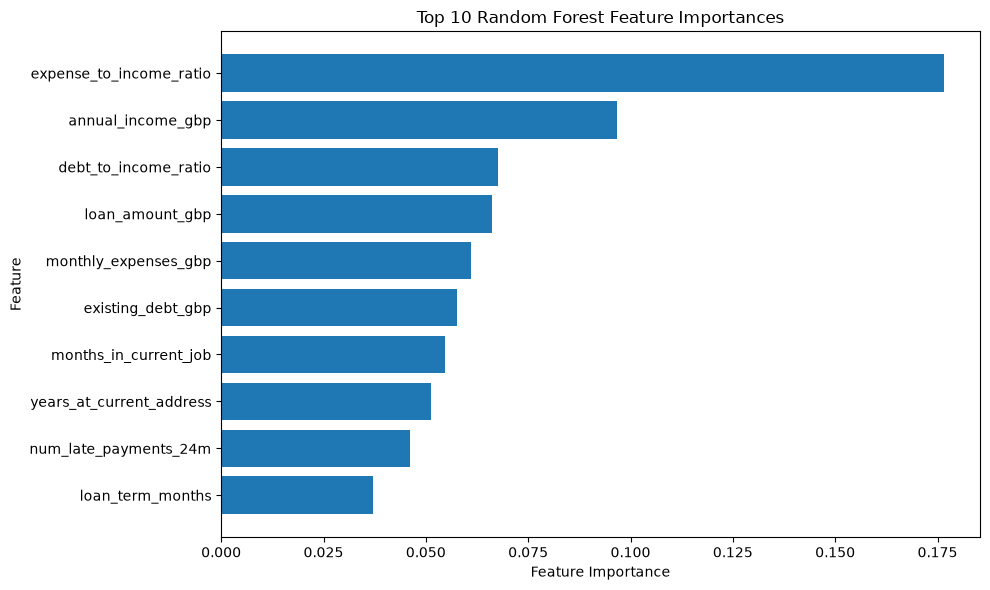

In [201]:
top_features = feature_importance.head(10).sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

In [202]:
errors = X_test.copy()

errors["actual"] = y_test
errors["predicted"] = rf_pred

In [203]:
errors[errors["actual"] != errors["predicted"]].head()

,num_dependents,months_in_current_job,annual_income_gbp,monthly_expenses_gbp,years_at_current_address,existing_debt_gbp,num_existing_credit_lines,num_late_payments_24m,credit_history,has_savings_account,...,loan_purpose_Home improvement,loan_purpose_Medical,loan_purpose_Other,application_channel_Broker,application_channel_Online,application_channel_Phone,debt_to_income_ratio,expense_to_income_ratio,actual,predicted
1509,3,72,21280,1990,0.7,0,0,3,2,1,...,0,0,0,1,0,0,0.000000,1.122180,1,0
4471,1,86,28680,2510,1.8,0,5,0,1,0,...,0,1,0,0,1,0,0.000000,1.050209,0,1
1507,1,18,16320,2030,2.1,0,2,0,0,1,...,1,0,0,0,1,0,0.000000,1.492647,1,0
3981,1,62,19160,1000,26.3,4490,1,2,3,1,...,0,0,0,0,1,0,0.234342,0.626305,1,0
4427,2,0,6500,1960,1.6,4770,5,3,1,0,...,1,0,0,0,1,0,0.733846,3.618462,0,1


In [204]:
errors["default_probability"] = rf_prob

In [205]:
false_negatives = errors[
    (errors["actual"] == 1) &
    (errors["predicted"] == 0)
]

false_negatives.sort_values(
    by="default_probability"
).head()

,num_dependents,months_in_current_job,annual_income_gbp,monthly_expenses_gbp,years_at_current_address,existing_debt_gbp,num_existing_credit_lines,num_late_payments_24m,credit_history,has_savings_account,...,loan_purpose_Medical,loan_purpose_Other,application_channel_Broker,application_channel_Online,application_channel_Phone,debt_to_income_ratio,expense_to_income_ratio,actual,predicted,default_probability
5757,1,72,43040,1930,4.9,0,2,1,0,1,...,0,0,0,0,1,0.0,0.538104,1,0,0.010
3767,0,34,116480,4570,8.5,0,3,0,1,0,...,0,0,0,1,0,0.0,0.470810,1,0,0.030
2006,1,19,89150,2730,9.1,0,0,0,2,1,...,0,0,0,1,0,0.0,0.367471,1,0,0.045
1178,0,105,32980,1760,8.5,0,0,1,2,0,...,0,0,0,0,0,0.0,0.640388,1,0,0.055
1687,0,27,35590,1800,14.3,0,3,1,1,1,...,0,0,0,1,0,0.0,0.606912,1,0,0.065


In [206]:
X_test.loc[5757].to_frame(name="Applicant 5757")

,Applicant 5757
num_dependents,1.000000
months_in_current_job,72.000000
annual_income_gbp,43040.000000
monthly_expenses_gbp,1930.000000
years_at_current_address,4.900000
existing_debt_gbp,0.000000
num_existing_credit_lines,2.000000
num_late_payments_24m,1.000000
credit_history,0.000000
has_savings_account,1.000000


### Example of a Badly Handled Applicant

Applicant 5757 provides an example of a significant model error.

The applicant actually defaulted within 24 months, but the Random Forest assigned only a 1% probability of default and predicted that they would not default.

Several features appear relatively low-risk, including permanent employment, six years in the current job, no existing debt, no previous declined application, and a good encoded credit history.

The applicant did have one late payment in the previous 24 months and a relatively small savings balance, but these were not sufficient for the model to correctly identify the eventual default.

This example demonstrates an important limitation of the system. Even when the model is highly confident, its prediction may still be incorrect. The model should therefore support human decision-making rather than be treated as an infallible automated decision maker.

In [207]:
false_positives = errors[
    (errors["actual"] == 0) &
    (errors["predicted"] == 1)
]

false_positives.sort_values(
    by="default_probability",
    ascending=False
).head()

,num_dependents,months_in_current_job,annual_income_gbp,monthly_expenses_gbp,years_at_current_address,existing_debt_gbp,num_existing_credit_lines,num_late_payments_24m,credit_history,has_savings_account,...,loan_purpose_Medical,loan_purpose_Other,application_channel_Broker,application_channel_Online,application_channel_Phone,debt_to_income_ratio,expense_to_income_ratio,actual,predicted,default_probability
4851,1,0,17160,1830,5.7,8570,4,2,1,1,...,0,0,0,1,0,0.499417,1.279720,0,1,0.905
4065,1,30,19500,1780,5.9,15290,1,3,1,1,...,0,0,0,0,0,0.784103,1.095385,0,1,0.870
5679,1,15,28000,2460,4.3,21910,3,0,1,0,...,0,0,0,0,0,0.782500,1.054286,0,1,0.850
1373,0,63,22520,2210,4.8,6080,4,2,1,1,...,0,0,0,1,0,0.269982,1.177620,0,1,0.835
4202,1,19,17150,1750,3.8,4680,5,4,3,0,...,0,0,0,1,0,0.272886,1.224490,0,1,0.820


In [208]:
X_test.loc[4851].to_frame(name="Applicant 4851")

,Applicant 4851
num_dependents,1.000000
months_in_current_job,0.000000
annual_income_gbp,17160.000000
monthly_expenses_gbp,1830.000000
years_at_current_address,5.700000
existing_debt_gbp,8570.000000
num_existing_credit_lines,4.000000
num_late_payments_24m,2.000000
credit_history,1.000000
has_savings_account,1.000000


### Example of a False Positive

Applicant 4851 provides an example of a confident false positive.

The Random Forest assigned this applicant a 90.5% probability of default, but the applicant did not default within 24 months.

The applicant had several characteristics that could be interpreted as higher risk, including unemployment, relatively low income, high monthly expenses, existing debt, multiple credit lines, recent late payments, and a high expense-to-income ratio.

However, the applicant also had savings, no previous declined application, an existing checking account, and a stable residential history.

This example demonstrates that even a high predicted probability does not guarantee that an applicant will default.

In a real lending environment, this type of error could lead to an applicant being unfairly declined or offered less favourable terms. For this reason, model predictions should be supported by explanation, review, and appropriate human oversight.